[![Mở trong Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/thanhmk/hocmaytrongtaichinh/blob/main/Module_5/L2.ipynb)

## HỌC MÁY TRONG TÀI CHÍNH
MODULE 5 | BÀI 2


---

# **MÁY VECTOR HỖ TRỢ TRONG THỰC TẾ**

|  |  |
|:---|:---|
|**Thời gian đọc** |  20 phút |
|**Kiến thức nền** | Phân loại, máy vector hỗ trợ, cây quyết định.  |
|**Từ khóa** |Siêu tham số, biến lỏng, lợi suất, đường cong ROC.  |


---

In [ ]:
# Chuẩn bị môi trường trên Colab (chạy ô này một lần trước khi chạy các ô khác)
import os, urllib.request, urllib.parse

BASE = "https://raw.githubusercontent.com/thanhmk/hocmaytrongtaichinh/main/Module_5/"
FILES = ['data_l3.csv']
for f in FILES:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + urllib.parse.quote(f), f)
        print("Đã tải:", f)

*Ở bài trước, ta đã trình bày phương pháp luận của máy vector hỗ trợ. Bài này áp dụng nó vào một bài toán phân tích dự báo.*

## **1. Giới thiệu**

Trong bài này, ta sẽ cài đặt SVM cho một chiến lược giao dịch chỉ số Luxembourg (LUXXX) dựa trên các chỉ số quốc gia khác cùng với các chỉ báo kỹ thuật. Chiến lược là mua/bán khống khi dự báo lợi suất LUXXX thay đổi 0,25%. Vị thế mua/bán khống dựa trên việc thị trường đang xu hướng tăng hay giảm. Cần nhớ rằng chiến lược này không tính đến chi phí giao dịch, nhưng bài được thiết kế để cho thấy tính thực tiễn của SVM trong phân tích dự báo cho các bài toán tài chính.

Ta bắt đầu bằng việc nạp các gói cần thiết.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import svm
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier

Dữ liệu chứa giá đóng cửa hằng tuần của các chỉ số có trong tệp csv sau, kèm theo ngày. Ta nạp dữ liệu này rồi xem bằng lệnh head().

Nếu bạn lưu tệp csv cùng chỗ với notebook, hãy dùng các ô không bị đóng chú thích bên dưới. Hãy dùng các ô đang chú thích nếu bạn lưu csv ở nơi khác. Biến "loc" là đường dẫn đến tệp csv mà bạn cần chỉ định.

In [2]:
# loc = "ENTER YOUR FULL PATH TO LOCATION OF DATA FILE HERE"
data_df = pd.read_csv("data_l3.csv")
data_df.head(3)

,Date,LUXXX,MSCI ARGENTINA,BLP ORIENTE MEDIO,MSCI AUSTRALIA,MSCI AUSTRIA,MSCI BELGIUM,MSCI BRAZIL,MSCI CANADA,MSCI CHINA,...,MSCI NORWAY,MSCI PERU,MSCI RUSSIA,MSCI SINGAPORE,MSCI SOUTH AFRICA,MSCI SPAIN,MSCI SWEDEN,MSCI SWITZERLAND,MSCI UK,MSCI USA
0,1-Jan-16,1390.716,2376.29,3525.9150,1068.79,106.70,105.38,1036.23,1663.27,59.47,...,2373.17,811.96,404.73,1507.8101,1255.75,108.40,11136.65,1148.37,1818.40,1949.70
1,8-Jan-16,1291.267,2260.85,3280.6683,1005.56,97.66,99.35,952.01,1586.18,54.63,...,2209.38,751.09,388.05,1437.6600,1177.76,101.00,10389.93,1075.30,1722.00,1831.88
2,15-Jan-16,1257.086,2217.50,3118.2981,985.38,93.54,97.32,904.64,1541.08,51.54,...,2095.60,720.23,344.45,1372.9800,1133.72,97.34,10042.32,1056.01,1692.43,1789.56


Cột 'Date' đang ở dạng chuỗi; do đó ta chuyển nó sang dạng datetime.

In [3]:
# Convert string to datetime
data_df["Date"] = pd.to_datetime(data_df["Date"])

C:\Users\Admin\AppData\Local\Temp\ipykernel_2068\616100313.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data_df["Date"] = pd.to_datetime(data_df["Date"])


Bên dưới là nơi ta chỉ định cột mục tiêu. Trong trường hợp của ta, đó là chỉ số LUXXX. Cần tính lợi suất của LUXXX vì chiến lược của ta dựa trên lợi suất theo tuần. Các chỉ số còn lại được chuyển thành lợi suất thay vì giá. Việc này đạt được hai điều: đưa các đặc trưng về cùng một đơn vị, và nắm bắt được biến động của giá.

In [4]:
# Set Target Index for predicting
target_ETF = "LUXXX"

# Use returns instead of prices for other Indices
# Other Indices used as Index_features
ETF_features = data_df.loc[:, ~data_df.columns.isin(["Date", target_ETF])].columns
data_df[ETF_features] = data_df[ETF_features].pct_change()

data_df[target_ETF + "_returns"] = data_df[target_ETF].pct_change()

Ô bên dưới tính cột Target và chuyển nó thành biến nhị phân dạng phân loại. Ta ký hiệu 1 khi lợi suất tuyệt đối của LUXXX vượt 0,25% và 0 trong trường hợp còn lại. Ở thị trường giảm, ta tìm cách bán khống nếu giá giảm hơn ngưỡng này, và ta mua vào ở thị trường tăng. Mục tiêu ở đây là dự báo phần trăm thay đổi vượt một ngưỡng. Lưu ý ta dịch cột mục tiêu đi một tuần để khớp kỳ dự báo với kỳ có sẵn của các biến dự báo khác. Thuật toán học máy cần nhãn và giá trị đặc trưng/biến dự báo nằm trên cùng một dòng hay một quan sát.

In [5]:
# Create Target Column.
# Shift period for target column
data_df[target_ETF + "_returns" + "_Shift"] = data_df[target_ETF + "_returns"].shift(-1)

# Strategy to take long position for anticipated returns of 0.5%
data_df["Target"] = np.where(
    (data_df[target_ETF + "_returns_Shift"].abs() > 0.025), 1, 0
)

Nên xem tập dữ liệu có mất cân bằng nào không. Tỷ lệ 34,5% cho nhóm mục tiêu 1 không cho thấy mất cân bằng.

In [6]:
# Checking target proportion
round(data_df["Target"].sum() / len(data_df), 4)

np.float64(0.3452)

Bây giờ ta đã có nhóm Target, ta có thể chọn các chỉ số nào đóng góp vào việc dự báo nhóm mục tiêu. Ta dùng công cụ độ quan trọng của đặc trưng trong `Sklearn` cho cây quyết định để làm việc này. Ta xem độ quan trọng tích lũy của các đặc trưng có đóng góp > 0.

In [7]:
# Preparing for Train/Test split

NoNaN_df = data_df.dropna()
X = NoNaN_df[ETF_features]

X = X.iloc[:, :]  # .values
y = NoNaN_df.loc[:, "Target"]  # .values

del NoNaN_df

# from sklearn.cross_validation import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

# USE DECISION TREE FOR FEATURE IMPORTANCE
# Fitting Decision Tree Classification to the Training set


DTree = DecisionTreeClassifier(
    criterion="entropy",
    random_state=0,
    max_depth=8,
    min_samples_leaf=30,
    min_samples_split=20,
    #                               , class_weight=classweight
)
DTree.fit(X_train, y_train)

feature_importances = pd.DataFrame(
    DTree.feature_importances_,
    index=X.iloc[:, :].columns,  # don't want the last Target column
    columns=["importance"],
).sort_values("importance", ascending=False)

feature_importances["Cumul_Imp"] = feature_importances.cumsum().iloc[:, :]
# If you want to see only those that explain a % of variation
pct_var = 1.0
feature_importances = feature_importances[(feature_importances["Cumul_Imp"] <= pct_var)]

Độ quan trọng tích lũy cho thấy chỉ có 4 chỉ số đóng góp, là MSCI KOREA, DENMARK, FRANCE và NORWAY. Điều này giảm đáng kể số đặc trưng và cũng giảm thời gian chạy khi tinh chỉnh siêu tham số.

              importance      Variable
MSCI KOREA      0.436123    MSCI KOREA
MSCI DENMARK    0.219591  MSCI DENMARK
MSCI FRANCE     0.196979   MSCI FRANCE
MSCI NORWAY     0.147308   MSCI NORWAY


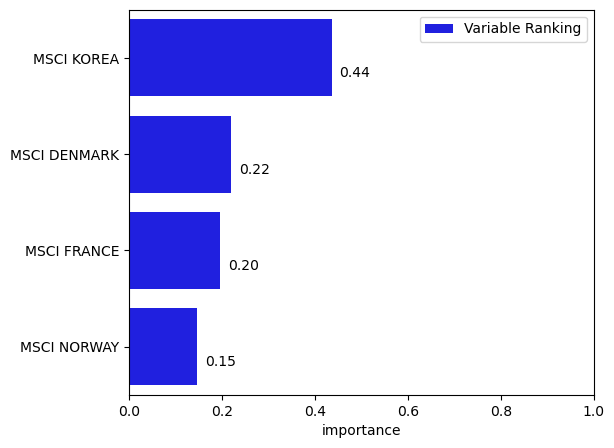

In [8]:
# PLOT IMPORTANCE

# Example data
cols = feature_importances.index
y_pos = np.arange(len(cols))
performance = feature_importances.importance

df2plot = pd.DataFrame(data=performance, index=feature_importances.index)
df2plot["Variable"] = feature_importances.index
df2plot = df2plot[df2plot["importance"] > 0.000]

print(df2plot)

f, ax = plt.subplots(figsize=(6, 5))

sns.barplot(
    x="importance", y="Variable", data=df2plot, label="Variable Ranking", color="b"
)

ax.set(xlim=(0, 1), ylabel="", xlabel="importance")

for p in ax.patches:
    width = p.get_width()
    ax.text(
        width + 0.05,
        p.get_y() + p.get_height() / 2.0 + 0.2,
        "{:1.2f}".format(width),
        ha="center",
    )

**Hình 1: Mức đóng góp độ quan trọng của bốn biến dự báo**

In [9]:
# Indices to add value in prediction
ETF_ImpFeatures = []
for i in df2plot["Variable"].values:
    ETF_ImpFeatures.append(i)

ETF_ImpFeatures

['MSCI KOREA', 'MSCI DENMARK', 'MSCI FRANCE', 'MSCI NORWAY']

## **2. Tạo các chỉ báo kỹ thuật**

Trong những chỉ báo kỹ thuật đầu tiên có giao cắt đường trung bình động ngắn hạn (SMA_5) và dài hạn (SMA_15). Ta dùng tỷ số (SMA_15/SMA_5) để nắm bắt mối quan hệ như một đặc trưng và các giao cắt. Ta dựa vào mô hình SVM để nắm bắt mối quan hệ giữa đặc trưng này và nhóm mục tiêu.

In [10]:
data_df["SMA_5"] = data_df[target_ETF].rolling(5).mean()
data_df["SMA_15"] = data_df[target_ETF].rolling(15).mean()
data_df["SMA_ratio"] = data_df["SMA_15"] / data_df["SMA_5"]

# Can drop SMA columns since not needed anymore.
data_df.drop(["SMA_5", "SMA_15"], axis=1, inplace=True)

Chỉ báo kỹ thuật tiếp theo ta xem là chỉ số sức mạnh tương đối (RSI), là một dao động động lượng. Chỉ báo này đo độ lớn của các thay đổi giá gần đây. Giá mục tiêu thường được xem là mua quá mức khi RSI > 70% và bán quá mức khi < 30%. Điều này dựa trên thay đổi giá của LUXXX trước tuần dự báo.

In [11]:
# shift the price of the target by 1 unit previous in time
data_df["Diff"] = data_df[target_ETF] - data_df[target_ETF].shift(1)
data_df["Up"] = data_df["Diff"]
data_df.loc[(data_df["Up"] < 0), "Up"] = 0

data_df["Down"] = data_df["Diff"]
data_df.loc[(data_df["Down"] > 0), "Down"] = 0
data_df["Down"] = abs(data_df["Down"])

data_df["avg_5up"] = data_df["Up"].rolling(5).mean()
data_df["avg_5down"] = data_df["Down"].rolling(5).mean()

data_df["avg_15up"] = data_df["Up"].rolling(15).mean()
data_df["avg_15down"] = data_df["Down"].rolling(15).mean()

data_df["RS_5"] = data_df["avg_5up"] / data_df["avg_5down"]
data_df["RS_15"] = data_df["avg_15up"] / data_df["avg_15down"]

data_df["RSI_5"] = 100 - (100 / (1 + data_df["RS_5"]))
data_df["RSI_15"] = 100 - (100 / (1 + data_df["RS_15"]))

data_df["RSI_ratio"] = data_df["RSI_5"] / data_df["RSI_15"]

# Can drop RS Calc columns columns
data_df.drop(
    ["Diff", "Up", "Down", "avg_5up", "avg_5down", "avg_15up", "avg_15down"],
    axis=1,
    inplace=True,
)

Tốc độ thay đổi (rate of change) là phần trăm thay đổi giá trong khoảng 15 tuần. Đây là tốc độ thay đổi dài hạn và cũng là một chỉ báo động lượng. Nó cũng dùng để phát hiện các trường hợp mua quá mức và bán quá mức.

In [12]:
data_df["RC"] = data_df[target_ETF].pct_change(periods=15)

Bây giờ ta kết hợp mọi đặc trưng, tức là thay đổi giá của các chỉ số cùng các chỉ báo kỹ thuật.

In [13]:
# all_feats
ETF_ImpFeatures.append("SMA_ratio")
ETF_ImpFeatures.append("RSI_ratio")
ETF_ImpFeatures.append("RC")

Bây giờ ta có thể huấn luyện mô hình. Để bắt đầu, ta chia dữ liệu huấn luyện/kiểm tra theo tỷ lệ 80/20.

In [14]:
# Train/Test split
# Train/Test split. No NaNs in the data.
NoNaN_df = data_df.dropna()
X = NoNaN_df[ETF_ImpFeatures]

X = X.iloc[:, :]  # .values
y = NoNaN_df.loc[:, "Target"]  # .values

del NoNaN_df

# from sklearn.cross_validation import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

Để xác định nhân tốt nhất và giá trị biến lỏng, ta dùng phương pháp tìm kiếm lưới bằng `GridSearchCV`. Hàm này sẽ khám phá không gian siêu tham số đã chỉ định để tìm giá trị tối ưu qua năm lần kiểm định chéo.

In [15]:
# defining parameter range
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100, 1000],
    #               'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
    "kernel": ["rbf", "linear", "poly"],
}

grid = GridSearchCV(svm.SVC(), param_grid, refit=True, verbose=3, cv=5)

# fitting the model for grid search
grid.fit(X_train, y_train)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
[CV 1/5] END ................C=0.01, kernel=rbf;, score=0.711 total time=   0.0s
[CV 2/5] END ................C=0.01, kernel=rbf;, score=0.711 total time=   0.0s
[CV 3/5] END ................C=0.01, kernel=rbf;, score=0.684 total time=   0.0s
[CV 4/5] END ................C=0.01, kernel=rbf;, score=0.703 total time=   0.0s
[CV 5/5] END ................C=0.01, kernel=rbf;, score=0.703 total time=   0.0s
[CV 1/5] END .............C=0.01, kernel=linear;, score=0.711 total time=   0.0s
[CV 2/5] END .............C=0.01, kernel=linear;, score=0.711 total time=   0.0s
[CV 3/5] END .............C=0.01, kernel=linear;, score=0.684 total time=   0.0s
[CV 4/5] END .............C=0.01, kernel=linear;, score=0.703 total time=   0.0s
[CV 5/5] END .............C=0.01, kernel=linear;, score=0.703 total time=   0.0s
[CV 1/5] END ...............C=0.01, kernel=poly;, score=0.711 total time=   0.0s
[CV 2/5] END ...............C=0.01, kernel=poly;

,estimator,SVC()
,param_grid,"{'C': [0.01, 0.1, ...], 'kernel': ['rbf', 'linear', ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,100


Các siêu tham số tốt nhất được chỉ ra bên dưới. Ta thấy nhân tốt nhất cho tập dữ liệu này là nhân đa thức với giá trị biến lỏng là 10.

In [16]:
# print best parameter after tuning
print(grid.best_params_)

# print how our model looks after hyper-parameter tuning
print(grid.best_estimator_)

{'C': 100, 'kernel': 'rbf'}
SVC(C=100)


Cuối cùng, ta có thể huấn luyện mô hình SVM với các siêu tham số đã chỉ định và so sánh nó với bộ phân loại cây quyết định chưa tinh chỉnh.

In [17]:
# Train with Tuned SVM
# Create a svm Classifier
clf_tuned = svm.SVC(
    random_state=0,
    C=grid.best_params_["C"],
    kernel=grid.best_params_["kernel"],
    probability=True,
)

clf_tuned.fit(X_train, y_train)


# Fitting Decision Tree Classification to the Training set as well

clf_tree = DecisionTreeClassifier(
    criterion="entropy",
    random_state=0,
    max_depth=8,
    min_samples_leaf=30,  # DM
    min_samples_split=20,
    #                               , class_weight=classweight
)  # DM
clf_tree.fit(X_train, y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,8
,min_samples_split,20
,min_samples_leaf,30
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


Từ kết quả bên dưới, ta thấy mô hình SVM tốt hơn đáng kể so với đoán ngẫu nhiên; tuy nhiên cách tiếp cận dựa trên cây tốt hơn một chút, với AUC cao hơn 4%.

## **3. Hiệu suất**

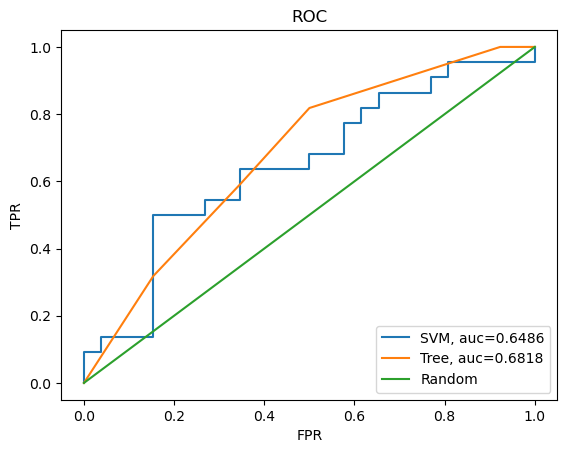

In [18]:
# Performance

# predicted probabilities generated by sklearn classifier
y_pred_proba = clf_tuned.predict_proba(X_test)
y_pred_probatree = clf_tree.predict_proba(X_test)

# SVM ROC dependencies
fpr, tpr, _ = roc_curve(y_test, y_pred_proba[:, 1])
# TREE ROC dependencies
fpr_tree, tpr_tree, _ = roc_curve(y_test, y_pred_probatree[:, 1])

auc = round(roc_auc_score(y_test, y_pred_proba[:, 1]), 4)
auc_tree = round(roc_auc_score(y_test, y_pred_probatree[:, 1]), 4)

# SVM Model
plt.plot(fpr, tpr, label="SVM, auc=" + str(auc))
# Tree model
plt.plot(fpr_tree, tpr_tree, label="Tree, auc=" + str(auc_tree))
# Random guess model
plt.plot(fpr, fpr, "-", label="Random")
plt.title("ROC")
plt.ylabel("TPR")
plt.xlabel("FPR")

plt.legend(loc=4)
plt.show()

**Hình 2. Đường cong ROC của ba mô hình**

## **4. Kết luận**
Bài này tập trung vào cài đặt mô hình SVM bằng Python cho một bài toán phân tích dự báo, cụ thể là chiến lược giao dịch vị thế mua một chỉ số. Ta cũng đưa các chỉ báo kỹ thuật vào làm biến dự báo. Ta thấy SVM cho kết quả tốt hơn đoán ngẫu nhiên, và kết quả không quá xa so với bộ phân loại cây quyết định. Như một bài tập, bạn có thể điều chỉnh notebook này để xem cả bộ phân loại cây quyết định đã tinh chỉnh siêu tham số.
Ở bài tiếp theo, ta sẽ xem một mô hình rất hiệu quả với dữ liệu phi tuyến, là mạng nơ-ron nhân tạo.